# 13 · Optimizers: GD vs SGD vs mini-batch, momentum, Nesterov and Adagrad

**Lectures:** *Optimizers in Neural Networks* (01-09-2026) and *SGD with Momentum, and Adagrad* (02-09-2026) · **Notes:** `../notes/13_optimizers_gd_sgd_momentum_adagrad.md`

Every optimizer starts from the same rule, **W_new = W_old − η·∂L/∂W**, and changes one of two things:
1. **How much data** feeds each gradient: all of it (GD), one record (SGD) or a batch (mini-batch SGD). *(01-09)*
2. **What the step is made of**: the raw gradient, a running **velocity** of past gradients (momentum, Nesterov), or a gradient divided by a **per-parameter history** (Adagrad). *(02-09)*

In this notebook you will:
1. Count the iterations per epoch for 10,000 records (1 / 10,000 / 10) and watch the three paths on a real loss surface.
2. Time them: which one is actually fastest?
3. Build momentum by hand, check it against PyTorch, verify the **1/(1 − β)** speed-up, and test the "**2–5× fewer iterations**" claim on the lecture's ravine.
4. Build Adagrad by hand, see why **rare features keep big steps**, and watch its learning rate **shrink until training stalls**.
5. Compare all of them fairly on a real network.

Runs in about 2 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
torch.manual_seed(0); np.random.seed(0)

## Part 1 (01-09): how much data per update?

A linear model ŷ = w·x + b on **10,000 records**, loss = mean squared error. The true values are w = 3, b = −2.

> **Small correction to the handout:** it writes "Loss = y − ŷ". That's the **error** of one prediction, and it can be negative. A **loss** turns errors into one number to minimise, e.g. MSE = mean((y − ŷ)²) (chapter 06). The optimizer minimises the loss, not the raw error.

In [2]:
N = 10_000
rng = np.random.default_rng(0)
X = rng.normal(0, 1, N); Y = 3 * X - 2 + rng.normal(0, 0.5, N)

def grads(w, b, idx):
    err = (w * X[idx] + b) - Y[idx]
    return 2 * np.mean(err * X[idx]), 2 * np.mean(err)          # dL/dw, dL/db of the MSE on these records

def mse(w, b): return np.mean((w * X + b - Y) ** 2)

def run(batch_size, epochs=1, lr=0.05, w=-3.0, b=3.0, seed=0):
    r = np.random.default_rng(seed)
    path, iters = [(w, b)], 0
    t0 = time.perf_counter()
    for _ in range(epochs):
        order = r.permutation(N)
        for start in range(0, N, batch_size):
            gw, gb = grads(w, b, order[start:start + batch_size])
            w, b = w - lr * gw, b - lr * gb                  # the SAME update rule for all three
            iters += 1; path.append((w, b))
    return np.array(path), iters, time.perf_counter() - t0

for name, bs in [("Gradient Descent (all 10,000)", N), ("SGD (1 record)", 1), ("Mini-batch SGD (1,000)", 1000)]:
    _, iters, secs = run(bs)
    print(f"{name:<31} iterations in 1 epoch = {iters:>6,}   (formula: {N} / {bs} = {N // bs:,})")

Gradient Descent (all 10,000)   iterations in 1 epoch =      1   (formula: 10000 / 10000 = 1)
SGD (1 record)                  iterations in 1 epoch = 10,000   (formula: 10000 / 1 = 10,000)
Mini-batch SGD (1,000)          iterations in 1 epoch =     10   (formula: 10000 / 1000 = 10)


Exactly the lecture's numbers: **1**, **10,000** and **10** iterations per epoch. The update rule never changed; only the **amount of data behind each gradient** did.

### The three paths on the loss surface
Each optimizer gets the same budget of **30 updates** (for GD that's 30 epochs; for SGD 30 single records).

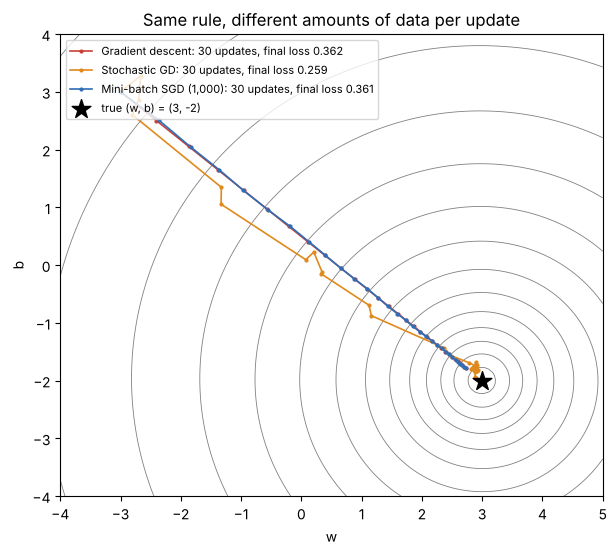

best possible loss (noise level): about 0.25


In [3]:
ws, bs_ = np.meshgrid(np.linspace(-4, 5, 120), np.linspace(-4, 4, 120))
Z = np.array([[mse(w_, b_) for w_ in ws[0]] for b_ in bs_[:, 0]])
fig, ax = plt.subplots(figsize=(7, 6))
ax.contour(ws, bs_, Z, levels=np.geomspace(0.3, 80, 14), colors="grey", linewidths=0.6)
for name, bsz, col, ep in [("Gradient descent", N, "#c8403a", 30), ("Stochastic GD", 1, "#e08a1e", 1), ("Mini-batch SGD (1,000)", 1000, "#2f6db5", 3)]:
    path, _, _ = run(bsz, epochs=ep)
    path = path[:31]
    ax.plot(path[:, 0], path[:, 1], ".-", color=col, ms=4, lw=1.2, label=f"{name}: 30 updates, final loss {mse(*path[-1]):.3f}")
ax.scatter([3], [-2], marker="*", s=200, c="k", zorder=5, label="true (w, b) = (3, -2)")
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.legend(fontsize=8, loc="upper left"); ax.set_title("Same rule, different amounts of data per update"); plt.show()
print(f"best possible loss (noise level): about {0.5 ** 2:.2f}")

- **Gradient descent** (red) takes a perfectly smooth, straight line: every step uses all 10,000 records, so there's no randomness.
- **Mini-batch (1,000)** (blue) lies almost exactly on top of it: an average over 1,000 records is already a very good estimate of the full gradient.
- **SGD** (orange) wobbles: each step follows one record's opinion. It still heads to the same minimum, and around it it keeps **jittering** instead of settling, as the lecture says.
- All three end near the true (3, −2). The best achievable loss is ≈ 0.25 (the noise in the data).

### Which is fastest? Count epochs, updates and seconds
Each runs until the loss is within 1% of the best achievable, at a learning rate that suits it (single records are noisy, so SGD needs a smaller one).

In [4]:
best = mse(*np.polyfit(X, Y, 1))
target = best * 1.01
for name, bsz, lr in [("Gradient Descent", N, 0.1), ("Mini-batch (1,000)", 1000, 0.1), ("Mini-batch (32)", 32, 0.02), ("SGD (1 record)", 1, 0.002)]:
    r = np.random.default_rng(0); w, b = -3.0, 3.0; updates = 0; t0 = time.perf_counter(); done = False
    for epoch in range(1, 201):
        order = r.permutation(N)
        for start in range(0, N, bsz):
            gw, gb = grads(w, b, order[start:start + bsz]); w, b = w - lr * gw, b - lr * gb; updates += 1
            if updates % (1 if bsz >= 1000 else 50) == 0 and mse(w, b) <= target:     # check the full loss now and then
                done = True; break
        if done: break
    secs = time.perf_counter() - t0
    print(f"{name:<20} reached loss {mse(w, b):.4f} after {updates:>6,} updates = {updates * bsz / N:6.2f} epochs of data, {secs * 1000:7.1f} ms")

Gradient Descent     reached loss 0.2493 after     23 updates =  23.00 epochs of data,     4.5 ms
Mini-batch (1,000)   reached loss 0.2494 after     23 updates =   2.30 epochs of data,     1.4 ms
Mini-batch (32)      reached loss 0.2475 after    150 updates =   0.48 epochs of data,     1.5 ms
SGD (1 record)       reached loss 0.2482 after  1,150 updates =   0.12 epochs of data,    10.1 ms


**Reading it (time to reach within 1% of the best loss):**

| | updates | data looked at | time |
|---|---|---|---|
| Gradient Descent | 23 | **23 full passes** | ~4.5 ms |
| Mini-batch (1,000) | 23 | 2.3 passes | ~1.4 ms |
| Mini-batch (32) | 150 | 0.48 passes | ~1.5 ms |
| SGD (1 record) | 1,150 | **0.12 passes** | ~10 ms |

- **GD** needs the fewest updates, but each one costs a full pass over the data: the most data read.
- **SGD** reads the least data (an eighth of one epoch), but needs **50× more updates**, and their per-update overhead (a Python loop over single records) makes it the **slowest in wall-clock time**: the lecture's "per-record overhead adds up".
- **Mini-batches** get the best of both: few passes and vectorised (fast) updates. That's why they're the default.
- *(Timings are in milliseconds on a tiny problem and vary between runs; the pattern is what matters. On GPUs, the advantage of batching is even larger.)*

## Part 2 (02-09): momentum

### 2a · The lecture's ravine: steep in θ₂, shallow in θ₁
J(θ) = ½(a·θ₁² + c·θ₂²) with **a = 0.05** (shallow) and **c = 1** (steep), starting at (−9, 2.2), like the lecture's figure. Vanilla gradient descent: **θ ← θ − η∇J**.

Momentum (the lecture's form): **v_t = β·v_{t−1} + η·∇J(θ_t)**, **θ_{t+1} = θ_t − v_t**, with v₀ = 0.
Nesterov: evaluate the gradient at the look-ahead point **θ̃ = θ_t − β·v_{t−1}**, then the same two lines.

vanilla GD (η = 1.8)           steps to reach the minimum region: 48
momentum (η = 0.3, β = 0.9)    steps to reach the minimum region: 69
Nesterov (η = 0.3, β = 0.9)    steps to reach the minimum region: 18
Adagrad (η = 1.5)              steps to reach the minimum region: 52


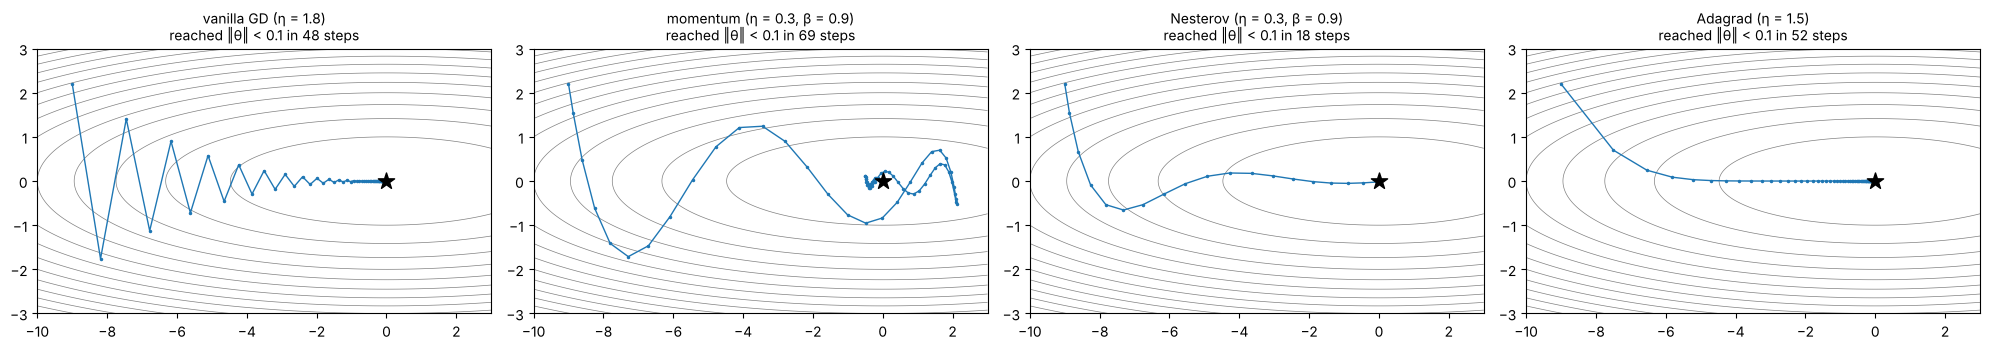

In [5]:
A = np.array([0.05, 1.0])                               # curvatures: shallow θ1, steep θ2
J = lambda th: 0.5 * np.sum(A * th ** 2)
gradJ = lambda th: A * th

def optimise(method, lr, beta=0.9, steps=2000, start=(-9.0, 2.2), tol=0.1, eps=1e-8):
    th = np.array(start, dtype=float); v = np.zeros(2); G = np.zeros(2); path = [th.copy()]
    for t in range(1, steps + 1):
        if method == "vanilla":
            th = th - lr * gradJ(th)
        elif method == "momentum":
            v = beta * v + lr * gradJ(th); th = th - v
        elif method == "nesterov":
            v = beta * v + lr * gradJ(th - beta * v); th = th - v
        elif method == "adagrad":
            g = gradJ(th); G = G + g * g; th = th - lr / np.sqrt(G + eps) * g
        path.append(th.copy())
        if np.linalg.norm(th) < tol:
            return t, np.array(path)
    return None, np.array(path)

runs = {"vanilla GD (η = 1.8)": ("vanilla", 1.8), "momentum (η = 0.3, β = 0.9)": ("momentum", 0.3),
        "Nesterov (η = 0.3, β = 0.9)": ("nesterov", 0.3), "Adagrad (η = 1.5)": ("adagrad", 1.5)}
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
t1, t2 = np.meshgrid(np.linspace(-10, 3, 200), np.linspace(-3, 3, 200))
for ax, (name, (m, lr)) in zip(axes, runs.items()):
    n, path = optimise(m, lr)
    ax.contour(t1, t2, 0.5 * (A[0] * t1 ** 2 + A[1] * t2 ** 2), levels=15, colors="grey", linewidths=0.5)
    ax.plot(path[:80, 0], path[:80, 1], ".-", ms=3, lw=1); ax.scatter([0], [0], marker="*", s=150, c="k", zorder=5)
    ax.set_title(f"{name}\nreached ‖θ‖ < 0.1 in {n} steps", fontsize=10); ax.set_xlim(-10, 3); ax.set_ylim(-3, 3)
    print(f"{name:<30} steps to reach the minimum region: {n}")
plt.tight_layout(); plt.show()

**What the four paths show (one hand-picked η each):**
- **Vanilla GD (η = 1.8):** the lecture's **zig-zag** across the steep θ₂ direction (each step overshoots and flips sign), then a slow crawl along the shallow θ₁ direction: 48 steps.
- **Momentum (η = 0.3, β = 0.9):** the zig-zag is damped, but it builds so much speed that it **overshoots past the minimum** (to θ₁ ≈ 2) and loops back: 69 steps, *slower* than vanilla here. The lecture's own momentum figure shows the same overshoot; that's the "**can overshoot if β or η is too large**" limitation.
- **Nesterov:** the look-ahead gradient brakes **before** overshooting: a smooth curve in only **18 steps**, the best of the four.
- **Adagrad (η = 1.5):** a big first step, then it slides straight along θ₁: 52 steps. It divides each axis by its own gradient history, so the steep and shallow directions get **different** step sizes automatically.

One hand-picked η per method isn't a fair comparison, so the next cell lets each method use its best η.

### 2b · Is "2–5× fewer iterations" right? A fair test
Each method gets its **best** learning rate from a grid (so nobody is handicapped by a bad η), on ravines of increasing difficulty (the ratio c/a of steep to shallow curvature).

In [6]:
lrs = np.geomspace(0.01, 3, 40)
np.seterr(over="ignore", invalid="ignore")         # some grid learning rates diverge on purpose; we just skip them
print(f"{'ravine (c/a)':>13} {'vanilla':>8} {'momentum':>9} {'Nesterov':>9} {'Adagrad':>8} {'momentum speed-up':>18}")
for ratio in [5, 20, 100, 1000]:
    A[:] = [1.0 / ratio, 1.0]
    best = {}
    for m in ["vanilla", "momentum", "nesterov", "adagrad"]:
        steps = [optimise(m, lr, steps=20000)[0] for lr in lrs]
        steps = [s for s in steps if s is not None]
        best[m] = min(steps) if steps else None
    print(f"{ratio:>13} {best['vanilla']:>8} {best['momentum']:>9} {best['nesterov']:>9} {best['adagrad']:>8} {best['vanilla'] / best['momentum']:>17.1f}×")
A[:] = [0.05, 1.0]

 ravine (c/a)  vanilla  momentum  Nesterov  Adagrad  momentum speed-up


            5       12        10        10       16               1.2×


           20       50        29        15       16               1.7×


          100      231        38        21       16               6.1×


         1000     2324       100       328       16              23.2×


**Steps to reach the minimum region, each method at its best learning rate:**
- On a mild ravine (5:1) momentum barely helps (**1.2×**). At 20:1 it's **1.7×**, at 100:1 **6.1×** and at 1000:1 **23×** faster than vanilla.
- So the lecture's "**often 2–5× fewer iterations**" is a typical middle value: **the worse the ravine, the bigger momentum's advantage**. On nearly round bowls it adds little.
- **Nesterov** usually beats classical momentum (10, 15, 21 steps) but not always (328 vs 100 at 1000:1). Its look-ahead helps, with no guarantee.
- **Adagrad took 16 steps on every ravine.** That's a **best case** for it: this ravine's steep and shallow directions line up exactly with the θ₁ and θ₂ axes, so per-parameter scaling cancels the difference completely. On real loss surfaces the directions are tilted and mixed, and the effect is much smaller.

### 2c · Why momentum speeds up: the 1/(1 − β) amplification
With a **constant** gradient g, the velocity v_t = β·v_{t−1} + η·g grows towards **η·g / (1 − β)**.

In [7]:
eta, g = 0.01, 1.0
for beta in [0.0, 0.5, 0.9, 0.99]:
    v, history = 0.0, []
    for t in range(2000):
        v = beta * v + eta * g; history.append(v)
    n95 = next(i for i, x in enumerate(history) if x >= 0.95 * eta * g / (1 - beta)) + 1
    print(f"β = {beta:<4}: step size settles at {v:.4f} = {v / eta:5.1f} × η   (formula 1/(1-β) = {1 / (1 - beta):5.1f})   reaches 95% of it after {n95} steps")

β = 0.0 : step size settles at 0.0100 =   1.0 × η   (formula 1/(1-β) =   1.0)   reaches 95% of it after 1 steps
β = 0.5 : step size settles at 0.0200 =   2.0 × η   (formula 1/(1-β) =   2.0)   reaches 95% of it after 5 steps
β = 0.9 : step size settles at 0.1000 =  10.0 × η   (formula 1/(1-β) =  10.0)   reaches 95% of it after 29 steps
β = 0.99: step size settles at 1.0000 = 100.0 × η   (formula 1/(1-β) = 100.0)   reaches 95% of it after 299 steps


- β = **0.9** → steps become **10×** bigger; β = **0.99** → **100×**, exactly the lecture's numbers. That's why a high β needs a smaller η.
- The build-up isn't instant: at β = 0.99 it takes about **300 steps** to reach 95% of full speed. Momentum "remembers" roughly the last 1/(1 − β) gradients.

### 2d · Unrolling the recursion, and checking PyTorch
The lecture says v_t is an exponentially weighted **sum of all past gradients**: v_t = η·Σᵢ β^(t−i)·∇J(θᵢ). Check on random gradients, and check that `torch.optim.SGD(momentum=β)` does the same thing.

In [8]:
rs = np.random.default_rng(1); gs = rs.normal(size=(50, 3)); eta, beta = 0.1, 0.9
v = np.zeros(3)
for gt in gs: v = beta * v + eta * gt
unrolled = eta * sum(beta ** (len(gs) - 1 - i) * gs[i] for i in range(len(gs)))
print("recursive v :", v.round(6)); print("unrolled sum:", unrolled.round(6))

# PyTorch stores buf = β·buf + g and steps θ -= η·buf; that's the lecture's v divided by η
theta_t = torch.tensor([1.0, -2.0], requires_grad=True); opt = torch.optim.SGD([theta_t], lr=eta, momentum=beta)
theta_m = np.array([1.0, -2.0]); v = np.zeros(2)
for step in range(20):
    loss = (theta_t ** 2 * torch.tensor([0.5, 3.0])).sum(); opt.zero_grad(); loss.backward(); opt.step()
    gm = 2 * theta_m * np.array([0.5, 3.0]); v = beta * v + eta * gm; theta_m = theta_m - v
print("\nafter 20 steps, PyTorch SGD(momentum=0.9):", theta_t.detach().numpy().round(6))
print("after 20 steps, the lecture's equations   :", theta_m.round(6))

recursive v : [ 0.222565 -0.08502  -0.522797]
unrolled sum: [ 0.222565 -0.08502  -0.522797]



after 20 steps, PyTorch SGD(momentum=0.9): [0.344667 0.42615 ]
after 20 steps, the lecture's equations   : [0.344667 0.426151]


Both agree to 6 decimals. PyTorch's bookkeeping differs (it keeps v/η), which is the lecture's point that the forms are "**equivalent up to a rescaling of the learning rate**". Keras/TensorFlow's EWMA form v = β·v + (1 − β)·g is equivalent to these if you use an η that is 1/(1 − β) times larger.

## Part 3 (02-09): Adagrad

**G_t = G_{t−1} + g_t ⊙ g_t** (G₀ = 0), **θ_{t+1} = θ_t − η/√(G_t + ε) ⊙ g_t**. Every parameter gets its **own** effective learning rate **η/√(G + ε)**.

### 3a · Rare features keep large steps
Logistic regression on 20,000 examples with 4 binary features: two **frequent** (present in 90% and 70% of examples) and two **rare** (present in 2% and 1%). A feature's gradient is zero whenever it's absent, so rare features accumulate a much smaller G.

frequent A (90%)  G =  4362.71   effective learning rate = 0.008   learned w = +0.48 (true +0.5)
frequent B (70%)  G =  3428.04   effective learning rate = 0.009   learned w = -0.50 (true -0.5)
rare C (2%)       G =    48.12   effective learning rate = 0.072   learned w = +1.63 (true +2.0)
rare D (1%)       G =    19.75   effective learning rate = 0.113   learned w = -2.17 (true -2.0)


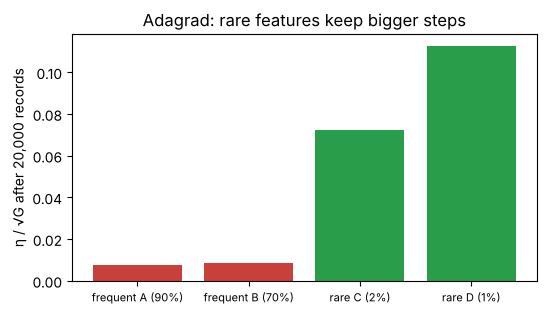

In [9]:
rs = np.random.default_rng(0); n = 20000
freq = np.array([0.9, 0.7, 0.02, 0.01])
Xs = (rs.random((n, 4)) < freq).astype(float)
true_w = np.array([0.5, -0.5, 2.0, -2.0])
ys = (rs.random(n) < 1 / (1 + np.exp(-(Xs @ true_w)))).astype(float)
w = np.zeros(4); G = np.zeros(4); eta, eps = 0.5, 1e-8
for i in range(n):                                     # one record at a time (SGD-style)
    p = 1 / (1 + np.exp(-Xs[i] @ w)); g = (p - ys[i]) * Xs[i]
    G += g * g; w -= eta / np.sqrt(G + eps) * g
eff = eta / np.sqrt(G + eps)
names = ["frequent A (90%)", "frequent B (70%)", "rare C (2%)", "rare D (1%)"]
for nm, e, gg, wt, wv in zip(names, eff, G, true_w, w):
    print(f"{nm:<17} G = {gg:8.2f}   effective learning rate = {e:.3f}   learned w = {wv:+.2f} (true {wt:+.1f})")
plt.figure(figsize=(6, 3.2)); plt.bar(names, eff, color=["#c8403a", "#c8403a", "#2a9d4b", "#2a9d4b"])
plt.ylabel("η / √G after 20,000 records"); plt.title("Adagrad: rare features keep bigger steps"); plt.xticks(fontsize=8); plt.show()

**Measured after 20,000 records (η = 0.5):**
- The frequent features piled up G ≈ 4,363 and 3,428, so their effective learning rates fell to **0.008–0.009**.
- The rare features (present in 2% and 1% of the records) only reached G ≈ 48 and 20, so they kept **0.072 and 0.113**: about **9–14× bigger steps**.
- That is exactly the lecture's Fig. 4 pattern (the handout's bar values are illustrative): when a rare feature finally shows up, Adagrad lets it learn a lot from that one example. All four weights ended near their true values (the rare ones less precisely: only 200–400 examples carry information about them).

### 3b · The decay problem: Adagrad's learning rate only shrinks
G is a sum of squares, so it can only grow, and η/√G can only fall. When the minimum is far away (or keeps moving, as in deep networks), Adagrad can **stall** before it gets there. RMSProp fixes this by replacing the sum with a **decaying average** (old gradients are forgotten).

Task: walk a single weight from 0 to 100 on L = ½(θ − 100)², with η = 1 for both methods.

Adagrad  step   10: θ =    4.97   size of this step |Δθ| = 0.3100
Adagrad  step  100: θ =   17.92   size of this step |Δθ| = 0.0928
Adagrad  step 1000: θ =   53.75   size of this step |Δθ| = 0.0227
Adagrad  step 3000: θ =   80.49   size of this step |Δθ| = 0.0079
RMSProp  step   10: θ =   16.79   size of this step |Δθ| = 1.1656
RMSProp  step  100: θ =   91.24   size of this step |Δθ| = 0.5595
RMSProp  step 1000: θ =  100.00   size of this step |Δθ| = 0.0000
RMSProp  step 3000: θ =  100.00   size of this step |Δθ| = 0.0000


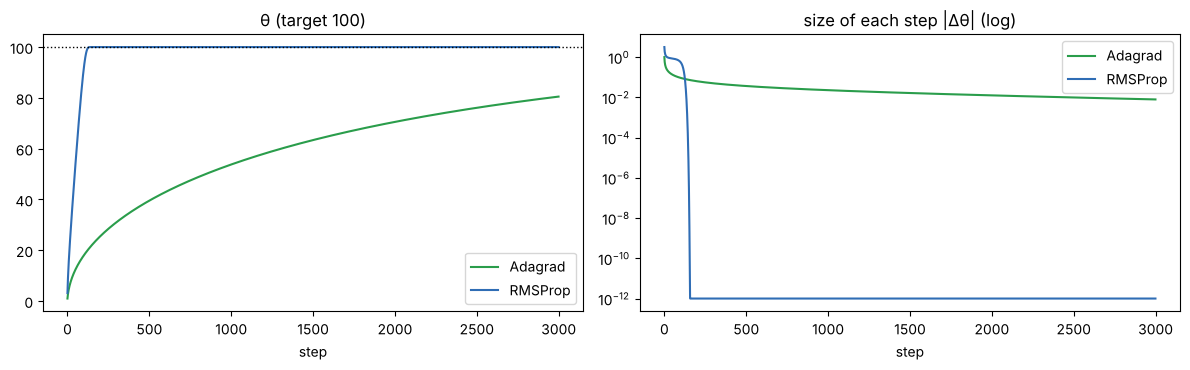

In [10]:
def walk(method, steps=3000, eta=1.0, rho=0.9, eps=1e-8):
    th, G, Eg = 0.0, 0.0, 0.0; ths, stepsizes = [], []
    for _ in range(steps):
        g = th - 100.0
        if method == "Adagrad":
            G += g * g; lr = eta / math.sqrt(G + eps)
        else:                                               # RMSProp: exponentially decaying average of g²
            Eg = rho * Eg + (1 - rho) * g * g; lr = eta / math.sqrt(Eg + eps)
        th -= lr * g; ths.append(th); stepsizes.append(abs(lr * g))
    return np.array(ths), np.array(stepsizes)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for m, col in [("Adagrad", "#2a9d4b"), ("RMSProp", "#2f6db5")]:
    ths, st = walk(m)
    axes[0].plot(ths, color=col, label=m); axes[1].semilogy(st + 1e-12, color=col, label=m)
    for t in [10, 100, 1000, 3000]:
        print(f"{m:<8} step {t:>4}: θ = {ths[t - 1]:7.2f}   size of this step |Δθ| = {st[t - 1]:.4f}")
axes[0].axhline(100, color="k", ls=":", lw=1); axes[0].set_title("θ (target 100)"); axes[1].set_title("size of each step |Δθ| (log)")
for ax in axes: ax.set_xlabel("step"); ax.legend()
plt.tight_layout(); plt.show()

**The stall, measured:**
- **Adagrad** after 3,000 steps is still only at **θ = 80.5** (the target is 100). Its step size fell from 0.31 (step 10) to **0.008** (step 3,000), and it keeps falling: G only ever grows.
- **RMSProp** (same η, but G replaced by a decaying average) was within 0.01 of **100** after 137 steps: once old large gradients are forgotten, the step size doesn't keep shrinking.

This is the lecture's "**learning rate can shrink to ≈ 0 and stall training**", and the reason RMSProp, Adadelta and Adam exist.

## Part 4: a fair race on a real network

The same digits MLP (64 → 128 → 64 → 10, ReLU), mini-batches of 32, 15 epochs, 3 seeds. Each optimizer gets its **best** learning rate from a small grid, picked on a **validation** split; we then report the **test** accuracy.

SGD             best lr 0.3    test accuracy 96.9% ± 0.4%   final training loss 0.0413


SGD + momentum  best lr 0.1    test accuracy 97.0% ± 0.9%   final training loss 0.0076


Nesterov        best lr 0.1    test accuracy 96.7% ± 0.7%   final training loss 0.0083


Adagrad         best lr 0.03   test accuracy 97.3% ± 0.4%   final training loss 0.0286


Adam (preview)  best lr 0.001  test accuracy 97.0% ± 0.1%   final training loss 0.0774


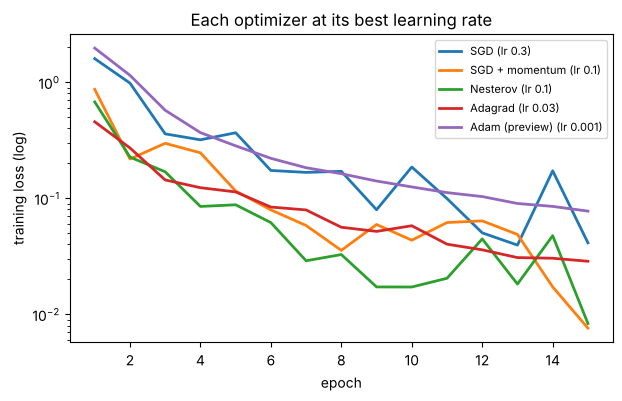

In [11]:
d = load_digits()
Xa, Xte, ya, yte = train_test_split(d.data / 16, d.target, test_size=0.25, random_state=0, stratify=d.target)
Xtr, Xva, ytr, yva = train_test_split(Xa, ya, test_size=0.2, random_state=0, stratify=ya)
T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
Xtr, Xva, Xte = T(Xtr), T(Xva), T(Xte); ytr, yva, yte = T(ytr, torch.long), T(yva, torch.long), T(yte, torch.long)

makers = {
    "SGD":            lambda p, lr: torch.optim.SGD(p, lr=lr),
    "SGD + momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    "Nesterov":       lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9, nesterov=True),
    "Adagrad":        lambda p, lr: torch.optim.Adagrad(p, lr=lr),
    "Adam (preview)": lambda p, lr: torch.optim.Adam(p, lr=lr),
}
grid = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]

def train(make, lr, seed, epochs=15):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
    opt = make(net.parameters(), lr); curve = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 32):
            idx = perm[i:i + 32]; loss = F.cross_entropy(net(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): curve.append(F.cross_entropy(net(Xtr), ytr).item())
    with torch.no_grad():
        return curve, (net(Xva).argmax(1) == yva).float().mean().item(), (net(Xte).argmax(1) == yte).float().mean().item()

results = {}
for name, make in makers.items():
    val = {lr: np.mean([train(make, lr, s)[1] for s in range(2)]) for lr in grid}
    lr_best = max(val, key=val.get)
    runs_ = [train(make, lr_best, s) for s in range(3)]
    results[name] = (lr_best, np.mean([r[0] for r in runs_], axis=0), [r[2] for r in runs_])
    print(f"{name:<15} best lr {lr_best:<6} test accuracy {np.mean(results[name][2]):.1%} ± {np.std(results[name][2]):.1%}   final training loss {results[name][1][-1]:.4f}")
plt.figure(figsize=(7, 4))
for name, (lr_b, curve, _) in results.items(): plt.semilogy(range(1, 16), curve, lw=2, label=f"{name} (lr {lr_b})")
plt.xlabel("epoch"); plt.ylabel("training loss (log)"); plt.legend(fontsize=8); plt.title("Each optimizer at its best learning rate"); plt.show()

**Honest reading:** at their **best** learning rates, all five land within one point of each other on test accuracy (96.7–97.3%, inside the seed-to-seed spread). On this small problem **the choice of learning rate matters more than the choice of optimizer**.

Differences do show in **training loss after 15 epochs**: momentum and Nesterov drive it lowest (0.008), plain SGD 0.041, Adagrad 0.029; Adam is highest here (0.077) at its grid-best lr of 0.001, while still matching on test accuracy. Faster optimisation ≠ better generalisation.

Note the **best learning rates differ a lot** (SGD 0.3, momentum 0.1, Adagrad 0.03, Adam 0.001), which is the 1/(1 − β) amplification and Adagrad/Adam's normalisation at work. **Never reuse one optimizer's learning rate for another.**

## Summary

| | Vanilla SGD | SGD + momentum | Adagrad |
|---|---|---|---|
| step made of | current gradient | running velocity of gradients | gradient ÷ √(sum of its past squares) |
| learning rate | one fixed η | one fixed η (amplified up to 1/(1−β)) | **per parameter**, shrinking |
| extra memory | none | v (same size as θ) | G (same size as θ) |
| extra setting | none | β (0.9–0.99) | none (ε ≈ 1e-8) |
| good for | simple problems | ravines, noisy mini-batches | sparse features (NLP, recommenders) |
| weakness | slow in ravines | can overshoot | learning rate → 0, can stall |

**Momentum (averaging over time) + per-parameter scaling (Adagrad's idea, with forgetting) = RMSProp/Adam**, the optimizers you'll see next.

## ✅ Check yourself
1. 50,000 records, batch 500: iterations per epoch for GD, SGD, mini-batch? *(1; 50,000; 100)*
2. Why can pure SGD's loss never settle exactly at the minimum with a fixed η? *(each single-record gradient is noisy, so it keeps jittering around the minimum)*
3. β = 0.95: maximum amplification of the step? *(1/(1 − 0.95) = 20×)*
4. v₀ = 0, β = 0.9, η = 0.1, gradients 1, 1, 1: v₁, v₂, v₃? *(0.1, 0.19, 0.271)*
5. What does Nesterov change? *(it evaluates the gradient at the look-ahead point θ − βv)*
6. Adagrad, η = 0.1, a parameter's gradients so far are 3 and 4: G and effective learning rate? *(G = 9 + 16 = 25; 0.1/√25 = 0.02)*
7. Why does Adagrad stall on long runs? *(G only grows, so η/√G → 0)*